# Avaliação final, responsabilidade e API

Modelo congelado `852606b93da31ade`. Este notebook apresenta a avaliação registrada em 310 exemplos temporais, sem reabrir seleção nem refazer o teste. As probabilidades representam classes do índice na população condicionada às detecções, não probabilidade física de incêndio. API: https://mba-risco-incendios.onrender.com/docs .

In [1]:
from pathlib import Path
import json, sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'submission/manifest.json').is_file() and (p/'src/fire_risk').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Abra o notebook dentro da pasta extraída ou do clone completo do projeto.')
sys.path.insert(0, str(ROOT/'src'))
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from fire_risk.submission import verify_submission, training_correlations
panel, manifest = verify_submission(ROOT)
def evidence(name):
    return json.loads((ROOT/'submission/evidence'/name).read_text(encoding='utf-8'))
print('Base consolidada íntegra:', len(panel), 'municípios/dia; partições:', manifest['splits'])
print('Modelo congelado:', manifest['model_id'])


Base consolidada íntegra: 1329 municípios/dia; partições: {'train': 764, 'test': 310, 'validation': 183, 'gap': 72}
Modelo congelado: 852606b93da31ade


## Resultado final e erros

O modelo vence a referência em F1 macro e identifica parte da classe alta, mas tem acurácia menor e desempenho fraco na classe média. O resultado não sustenta uso operacional. Reamostragem por dia considera parcialmente a dependência temporal, com apenas nove dias de teste; não garante generalização futura.

{
  "modelo": {
    "rows": 310,
    "accuracy": 0.535483870967742,
    "f1_macro": 0.4097179544065533,
    "recall_alto": 0.5689655172413793,
    "precision_macro": 0.42759963622746483,
    "recall_macro": 0.43648045339467184,
    "classification_report": {
      "baixo": {
        "precision": 0.8533333333333334,
        "recall": 0.579185520361991,
        "f1-score": 0.6900269541778976,
        "support": 221.0
      },
      "medio": {
        "precision": 0.07462686567164178,
        "recall": 0.16129032258064516,
        "f1-score": 0.10204081632653061,
        "support": 31.0
      },
      "alto": {
        "precision": 0.3548387096774194,
        "recall": 0.5689655172413793,
        "f1-score": 0.4370860927152318,
        "support": 58.0
      },
      "accuracy": 0.535483870967742,
      "macro avg": {
        "precision": 0.42759963622746483,
        "recall": 0.43648045339467184,
        "f1-score": 0.4097179544065533,
        "support": 310.0
      },
      "weighted avg

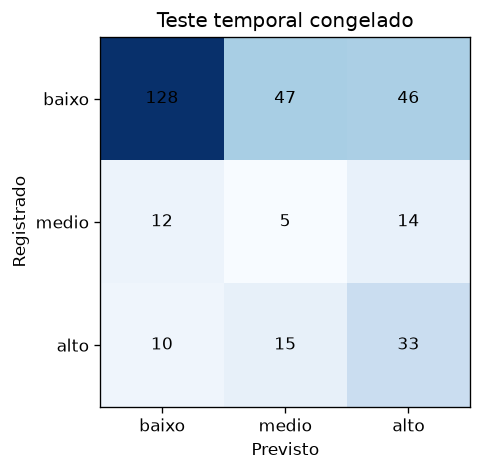

In [2]:
evaluation=evidence('evaluation.json')
print(json.dumps({'modelo':evaluation['metrics'],'referencia':evaluation['reference'],'incerteza':evaluation['uncertainty']},ensure_ascii=False,indent=2))
matrix=evaluation['metrics']['confusion_matrix']
plt.figure(figsize=(5,4)); plt.imshow(matrix,cmap='Blues')
for i,row in enumerate(matrix):
    for j,value in enumerate(row): plt.text(j,i,str(value),ha='center',va='center')
plt.xticks(range(3),['baixo','medio','alto']); plt.yticks(range(3),['baixo','medio','alto']); plt.xlabel('Previsto'); plt.ylabel('Registrado'); plt.title('Teste temporal congelado')


## Explicabilidade e vieses

Importância por permutação na validação: queda do F1 macro, incluindo valores negativos. As três primeiras variáveis são destacadas; importância global não é efeito causal ou explicação individual. Análises por UF, semana e cobertura incluem suporte e sinalizam grupos esparsos. Não afirmamos equidade ou ausência de viés com amostras insuficientes.

Três variáveis principais:    feature  mean_f1_decrease      std
  vento_d2          0.089014 0.025387
umidade_d2          0.067889 0.018386
  chuva_d2          0.028914 0.013982
Grupos: {
  "uf_code": {
    "12": {
      "rows": 1,
      "accuracy": 1.0,
      "f1_macro": 0.3333333333333333,
      "recall_alto": 0.0,
      "precision_macro": 0.3333333333333333,
      "recall_macro": 0.3333333333333333,
      "classification_report": {
        "baixo": {
          "precision": 1.0,
          "recall": 1.0,
          "f1-score": 1.0,
          "support": 1.0
        },
        "medio": {
          "precision": 0.0,
          "recall": 0.0,
          "f1-score": 0.0,
          "support": 0.0
        },
        "alto": {
          "precision": 0.0,
          "recall": 0.0,
          "f1-score": 0.0,
          "support": 0.0
        },
        "accuracy": 1.0,
        "macro avg": {
          "precision": 0.3333333333333333,
          "recall": 0.3333333333333333,
          "f1-score": 0.3

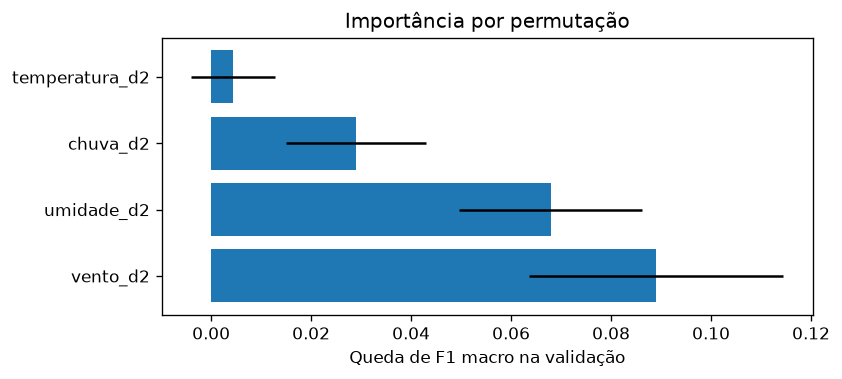

In [3]:
importance=pd.DataFrame(evidence('optimization.json')['explanation_validation'])
print('Três variáveis principais:',importance.head(3).to_string(index=False))
print('Grupos:',json.dumps(evaluation['groups'],ensure_ascii=False,indent=2))
plt.figure(figsize=(7,3)); plt.barh(importance['feature'],importance['mean_f1_decrease'],xerr=importance['std']); plt.xlabel('Queda de F1 macro na validação'); plt.title('Importância por permutação')


## Valor simulado e plano A/B

Custos são fictícios e foram definidos antes do teste; não são economia comprovada ou incêndios evitados. O plano completo em `docs/ab-plan.md` define sorteio por blocos geográficos, proteção contra contaminação, métricas independentes, amostra, duração e critérios de parada. O enunciado pede planejar o A/B, não executá-lo.

In [4]:
print('Custos: modelo',evaluation['simulated_cost'],'referência',evaluation['reference_simulated_cost'])
print(pd.DataFrame(evaluation['cost_sensitivity']).to_string(index=False))


Custos: modelo {'total': 5930.0, 'per_decision': 19.129032258064516, 'currency': 'BRL', 'kind': 'fictional_academic_simulation'} referência {'total': 13150.0, 'per_decision': 42.41935483870968, 'currency': 'BRL', 'kind': 'fictional_academic_simulation'}
 missed_high_multiplier  overalert_multiplier                                                                                                              model                                                                                                          reference  reference_minus_model
                    0.5                   0.5   {'total': 3265.0, 'per_decision': 10.53225806451613, 'currency': 'BRL', 'kind': 'fictional_academic_simulation'}   {'total': 7350.0, 'per_decision': 23.70967741935484, 'currency': 'BRL', 'kind': 'fictional_academic_simulation'}                 4085.0
                    0.5                   1.0   {'total': 4330.0, 'per_decision': 13.96774193548387, 'currency': 'BRL', 'kind': 'fictional_academic_

## Publicação, reprodução e conclusão

FastAPI com validação, exemplo em `configs/example-request.json`, dependências e Dockerfile. A evidência abaixo identifica o commit do serviço e o modelo; esta execução não faz chamadas de rede. O plano gratuito pode demorar após inatividade. A entrega está preparada para revisão acadêmica, ainda sem submissão ou aprovação. A reprodução desta apresentação usa o painel e evidências incluídos; a reconstrução desde os quatro CSVs está no README. Limites: janela curta, meteorologia D−2 com disponibilidade assumida, seleção por detecções e ausência de sazonalidade anual.

In [5]:
print(json.dumps(evidence('deployment.json'),ensure_ascii=False,indent=2))
print('Conclusão: protótipo acadêmico reproduzível para o índice observado, sem validação operacional.')


{
  "status": "live",
  "provider": "render",
  "verified_date": "2026-10-25",
  "public_url": "https://mba-risco-incendios.onrender.com",
  "docs_url": "https://mba-risco-incendios.onrender.com/docs",
  "http_verified": true,
  "health_status": 200,
  "prediction_status": 200,
  "invalid_input_status": 422,
  "model_id": "852606b93da31ade",
  "plan": "free",
  "auto_deploy": "off",
  "service_id": "srv-dbf994o473hc73caetb0",
  "deploy_id": "dep-dbf9less728c73ek5qvg",
  "deployed_commit": "f15f79870ac78286606eb2426d540f42064b55ac",
  "branch": "main",
  "operational_use_validated": false,
  "calendar_boundary_invalid_statuses": [
    422,
    422,
    422
  ]
}
Conclusão: protótipo acadêmico reproduzível para o índice observado, sem validação operacional.
